# 01 — EDA (W1)

Review volume over time, rating distribution, price vs reception, language mix for the
300-game subset. Numbers come from `data/processed/` (run `make data` first); the volume
chart reads the **raw** Mendeley review dates, because the processed sample is capped and
stratified per game and year and would distort volume. See `docs/DATA_CARD.md`.

In [1]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import polars as pl

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
con = duckdb.connect(str(ROOT / "data/processed/sga.duckdb"), read_only=True)
games = con.sql("SELECT * FROM games").pl()
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False})
INK, ACCENT = "#3b3f46", "#2f6fb0"
print(f"{games.height} games, {con.sql('SELECT count(*) FROM reviews').fetchone()[0]:,} sampled reviews")

300 games, 417,170 sampled reviews


## Review volume over time (raw Mendeley reviews, subset games)

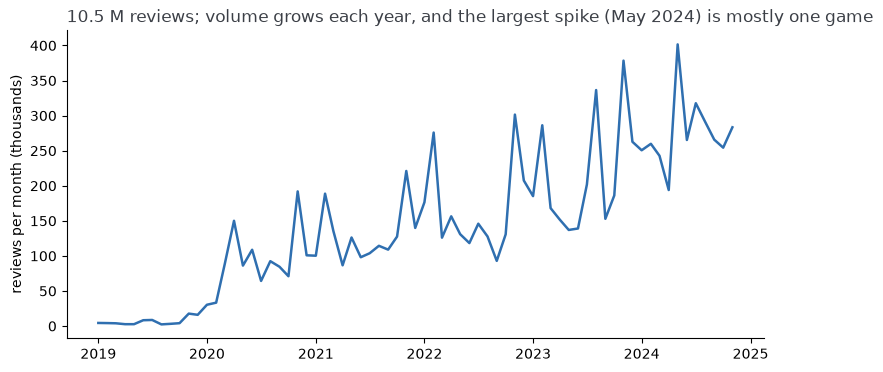

In [2]:
counts = pl.read_parquet(ROOT / "data/processed/review_counts.parquet")
paths = counts.join(games.select("appid"), on="appid")["path"].to_list()
dates = pl.concat(
    [
        pl.read_csv(p, columns=["post_date"], infer_schema_length=0, ignore_errors=True,
                    truncate_ragged_lines=True)
        for p in paths
    ]
).select(pl.col("post_date").str.strptime(pl.Date, "%B %d, %Y", strict=False).alias("d")).drop_nulls()
last_day = dates["d"].max()
monthly = (
    dates.filter(pl.col("d") >= pl.date(2019, 1, 1))
    .group_by(pl.col("d").dt.truncate("1mo").alias("month")).len().sort("month")
)
if last_day.day < 28:  # the dataset stops mid-month: drop the partial month
    monthly = monthly.filter(pl.col("month") < pl.date(last_day.year, last_day.month, 1))
fig, ax = plt.subplots()
ax.plot(monthly["month"], monthly["len"] / 1000, color=ACCENT, lw=1.8)
ax.set_ylabel("reviews per month (thousands)")
peak = monthly.sort("len", descending=True).row(0, named=True)
ax.set_title(f"{dates.height/1e6:.1f} M reviews; volume grows each year, and the largest spike "
             f"({peak['month']:%b %Y}) is mostly one game", loc="left", color=INK)
plt.show()

In [3]:
# who drives the peak month?
peak_month = monthly.sort("len", descending=True)["month"][0]
per_game = pl.concat(
    [
        pl.read_csv(p, columns=["post_date"], infer_schema_length=0, ignore_errors=True,
                    truncate_ragged_lines=True).with_columns(pl.lit(a).alias("appid"))
        for a, p in zip(counts.join(games.select("appid"), on="appid")["appid"], paths)
    ]
).with_columns(pl.col("post_date").str.strptime(pl.Date, "%B %d, %Y", strict=False).alias("d"))
(per_game.filter(pl.col("d").dt.truncate("1mo") == peak_month)
 .join(games.select("appid", "name"), on="appid").group_by("name").len()
 .sort("len", descending=True).head(5))

name,len
str,u32
"""HELLDIVERS™ 2""",165362
"""Hades II""",38299
"""V Rising""",12640
"""The Hungry Lamb: Traveling in …",10386
"""EA SPORTS FC™ 24""",9131


## Rating distribution (catalog positive ratio)

41 games have no votes in the catalog snapshot (ratio unknown) and are left out


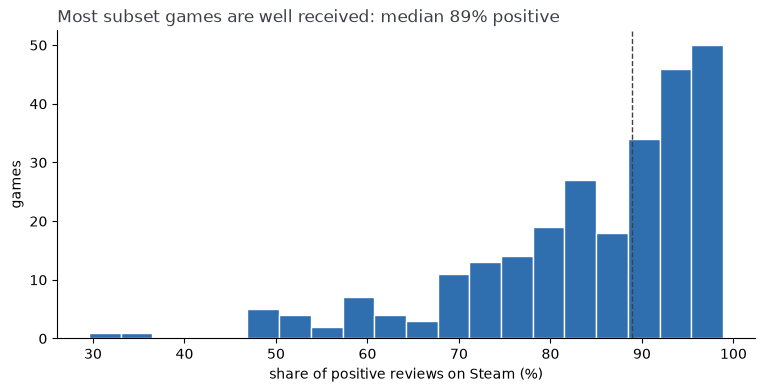

In [4]:
ratio = games["positive_ratio"].drop_nulls()
print(f"{games.height - ratio.len()} games have no votes in the catalog snapshot (ratio unknown) and are left out")
fig, ax = plt.subplots()
ax.hist(ratio * 100, bins=20, color=ACCENT, edgecolor="white")
ax.axvline(ratio.median() * 100, color=INK, ls="--", lw=1)
ax.set_xlabel("share of positive reviews on Steam (%)")
ax.set_ylabel("games")
ax.set_title(f"Most subset games are well received: median {ratio.median():.0%} positive", loc="left", color=INK)
plt.show()

## Price vs reception

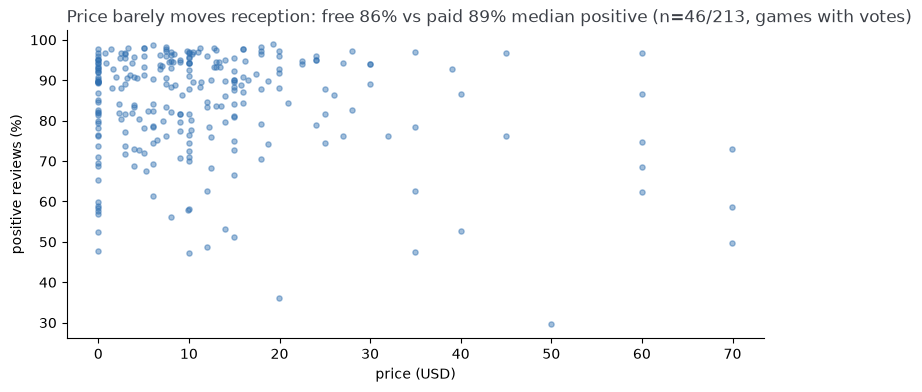

band,median,n
str,f64,u32
"""free""",0.860526,46
"""<$10""",0.896801,106
"""$10-20""",0.895313,70
"""$20-40""",0.871886,26
""">$40""",0.73018,11


In [5]:
pr = games.select("price_usd", "positive_ratio").drop_nulls()
bins = pr.with_columns(
    pl.col("price_usd").cut([0.01, 10, 20, 40], labels=["free", "<$10", "$10-20", "$20-40", ">$40"]).alias("band")
).group_by("band").agg(pl.col("positive_ratio").median().alias("median"), pl.len().alias("n"))
order = ["free", "<$10", "$10-20", "$20-40", ">$40"]
bins = bins.with_columns(pl.col("band").cast(pl.Utf8)).filter(pl.col("band").is_in(order))
bins = bins.sort(pl.col("band").replace_strict(order, list(range(len(order)))))
fig, ax = plt.subplots()
ax.scatter(pr["price_usd"], pr["positive_ratio"] * 100, s=14, alpha=0.45, color=ACCENT)
ax.set_xlabel("price (USD)")
ax.set_ylabel("positive reviews (%)")
free = pr.filter(pl.col("price_usd") == 0)["positive_ratio"]
paid = pr.filter(pl.col("price_usd") > 0)["positive_ratio"]
ax.set_title(f"Price barely moves reception: free {free.median():.0%} vs paid {paid.median():.0%} "
             f"median positive (n={free.len()}/{paid.len()}, games with votes)", loc="left", color=INK)
plt.show()
bins

## Language mix of the review sample

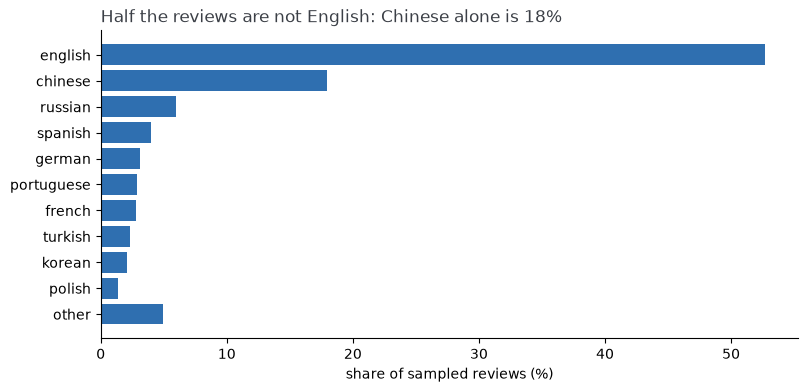

In [6]:
langs = con.sql("""
    SELECT language, count(*) AS n FROM reviews GROUP BY 1 ORDER BY n DESC
""").pl()
top = langs.head(10)
other = langs["n"][10:].sum()
labels = top["language"].to_list() + ["other"]
values = top["n"].to_list() + [other]
total = sum(values)
fig, ax = plt.subplots()
ax.barh(labels[::-1], [v / total * 100 for v in values[::-1]], color=ACCENT)
ax.set_xlabel("share of sampled reviews (%)")
ax.set_title("Half the reviews are not English: Chinese alone is 18%", loc="left", color=INK)
plt.show()

## Takeaways

- Review volume grows every year (1.1 M in 2020 to 3.1 M in 2024, partly because more
  subset games are on sale) and spikes on single-game events: in the peak month one title
  wrote 40% of all reviews. Trend tools must work per game, on equal-length windows, and
  report counts alongside shares.
- Reception is skewed positive; the balanced review sample must not be used as a
  reception estimate (use catalog `positive` / `negative`).
- 41 subset games (37 of them free-to-play) have no votes in the catalog snapshot; their
  reception is unknown, not 0%. Among games with votes, price barely moves reception
  (see the band table), so the W3 predictor needs genre, tags, developer track record
  and release timing; and it must not train on the vote-less games.
- Retrieval and the sentiment model must handle many languages, or filter explicitly.